# 1. Imports and Dataset

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns
%matplotlib inline

## Loading the kaggle dataset

In [138]:
df = pd.read_csv("Data/raw_data/train.csv")

# 2. Synthetic data genration

creating a working copy and extracting calendar information

In [3]:
synthetic_base = df.copy()

synthetic_base["date"] = pd.to_datetime(
    synthetic_base["date"]
)

synthetic_base["month"] = (
    synthetic_base["date"].dt.month
)

synthetic_base["day_of_week"] = (
    synthetic_base["date"].dt.day_name()
)

print(synthetic_base.columns.tolist())

['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'month', 'day_of_week']


## Building a lookup of historical sales and promotion

Grouping by store, product family, month and weekday gives the generator a pool of historical examples with a similar seasonal/calendar profile.

In [4]:
# Group historical data by store, family, month and weekday

historical_groups = synthetic_base.groupby(
    ["store_nbr", "family", "month", "day_of_week"]
)

# Create lookup dictionary
lookup = {
    key: group[["sales", "onpromotion"]].to_numpy()
    for key, group in historical_groups
}

print("Historical patterns prepared successfully!")
print("Number of pattern groups:", len(lookup))

Historical patterns prepared successfully!
Number of pattern groups: 149688


## Generating synthetic data for 2018

For each date and each store-family pair, one historical sales/promotion observation is randomly selected from the matching month and weekday group. A fixed random seed makes the sample reproducible.

In [5]:
# synthetic data for 2018
import numpy as np
import pandas as pd

# Random generator for reproducible results
rng = np.random.default_rng(42)

# Get all store-family combinations
combinations = [
    (store, family)
    for store in sorted(synthetic_base["store_nbr"].unique())
    for family in sorted(synthetic_base["family"].unique())
]

# Generate dates for 2018
dates = pd.date_range(
    start="2018-01-01",
    end="2018-12-31",
    freq="D"
)

synthetic_records = []

for date in dates:

    weekday = date.day_name()
    month = date.month

    daily_sales = []
    daily_promotions = []

    for store, family in combinations:

        key = (store, family, month, weekday)

        historical_values = lookup[key]

        random_index = rng.integers(
            0, len(historical_values)
        )

        selected = historical_values[random_index]

        daily_sales.append(selected[0])
        daily_promotions.append(selected[1])

    daily_data = pd.DataFrame({
        "date": date,
        "store_nbr": [x[0] for x in combinations],
        "family": [x[1] for x in combinations],
        "sales": daily_sales,
        "onpromotion": daily_promotions
    })

    synthetic_records.append(daily_data)

# Combine daily records
synthetic_2018 = pd.concat(
    synthetic_records,
    ignore_index=True
)

# Add derived features
synthetic_2018["day_of_week"] = (
    synthetic_2018["date"].dt.day_name()
)
synthetic_2018["month"] = (
    synthetic_2018["date"].dt.month
)

# Assign unique IDs after the original dataset
synthetic_2018.insert(
    0,
    "id",
    np.arange(
        len(df),
        len(df) + len(synthetic_2018)
    )
)

print("2018 synthetic data generated!")
print("Shape:", synthetic_2018.shape)
print("Date range:",
      synthetic_2018["date"].min(),
      "to",
      synthetic_2018["date"].max())

display(synthetic_2018.head())


2018 synthetic data generated!
Shape: (650430, 8)
Date range: 2018-01-01 00:00:00 to 2018-12-31 00:00:00


,id,date,store_nbr,family,sales,onpromotion,day_of_week,month
0,3000888,2018-01-01,1,AUTOMOTIVE,2.0,0.0,Monday,1
1,3000889,2018-01-01,1,BABY CARE,0.0,0.0,Monday,1
2,3000890,2018-01-01,1,BEAUTY,3.0,0.0,Monday,1
3,3000891,2018-01-01,1,BEVERAGES,1235.0,0.0,Monday,1
4,3000892,2018-01-01,1,BOOKS,0.0,0.0,Monday,1


## Generating synthetic data for 2019 to 2026

The loop extends the dataset year by year. 2026 is generated only through 2026-11-17 to match the project's forecast origin. IDs continue after the original data to avoid ID collisions.

In [6]:

import os
import numpy as np
import pandas as pd

# Folder for synthetic datasets
os.makedirs("Data/synthetic_data", exist_ok=True)

# Save the already generated 2018 dataset
synthetic_2018.to_csv(
    "Data/synthetic_data/synthetic_2018.csv",
    index=False
)

# Reproducible random generator
rng = np.random.default_rng(2026)

# Continue IDs after 2018
next_id = int(synthetic_2018["id"].max()) + 1

# Generate remaining years
for year in range(2019, 2027):

    start_date = f"{year}-01-01"

    if year == 2026:
        end_date = "2026-11-17"
    else:
        end_date = f"{year}-12-31"

    dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="D"
    )

    yearly_records = []

    for date in dates:

        weekday = date.day_name()
        month = date.month

        daily_sales = []
        daily_promotions = []

        for store, family in combinations:

            key = (store, family, month, weekday)

            historical_values = lookup[key]

            random_index = rng.integers(
                0, len(historical_values)
            )

            selected = historical_values[random_index]

            daily_sales.append(selected[0])
            daily_promotions.append(selected[1])

        daily_data = pd.DataFrame({
            "date": date,
            "store_nbr": [x[0] for x in combinations],
            "family": [x[1] for x in combinations],
            "sales": daily_sales,
            "onpromotion": daily_promotions
        })

        yearly_records.append(daily_data)

    # Combine records for this year
    synthetic_year = pd.concat(
        yearly_records,
        ignore_index=True
    )

    # Add derived date features
    synthetic_year["day_of_week"] = (
        synthetic_year["date"].dt.day_name()
    )
    synthetic_year["month"] = (
        synthetic_year["date"].dt.month
    )

    # Assign unique IDs
    synthetic_year.insert(
        0,
        "id",
        np.arange(
            next_id,
            next_id + len(synthetic_year)
        )
    )

    # Keep promotion values as integers
    synthetic_year["onpromotion"] = (
        synthetic_year["onpromotion"].astype(int)
    )

    # Save the year separately
    file_path = (
        f"Data/synthetic_data/synthetic_{year}.csv"
    )

    synthetic_year.to_csv(
        file_path,
        index=False
    )

    print(
        f"{year}: {len(synthetic_year):,} rows saved"
    )

    next_id += len(synthetic_year)

print("\nAll remaining synthetic datasets generated!")
print("Final ID:", next_id - 1)


2019: 650,430 rows saved
2020: 652,212 rows saved
2021: 650,430 rows saved
2022: 650,430 rows saved
2023: 650,430 rows saved
2024: 652,212 rows saved
2025: 650,430 rows saved
2026: 572,022 rows saved

All remaining synthetic datasets generated!
Final ID: 8779913


## Loading all generated synthetic yearly files

Using a file pattern avoids manually loading each year. Concatenating them creates one synthetic dataset for later combination.

In [7]:
import pandas as pd
import glob
import os

# Find all synthetic CSV files
synthetic_files = sorted(
    glob.glob("Data/synthetic_data/synthetic_*.csv")
)

# Load and combine synthetic files
synthetic_df = pd.concat(
    [pd.read_csv(file) for file in synthetic_files],
    ignore_index=True
)

print("Synthetic dataset shape:", synthetic_df.shape)

print("\nDate range:")
print(
    synthetic_df["date"].min(),
    "to",
    synthetic_df["date"].max()
)

print("\nFiles loaded:", len(synthetic_files))

Synthetic dataset shape: (5779026, 8)

Date range:
2018-01-01 to 2026-11-17

Files loaded: 9


# 3. Combining and validating the extended dataset

Both datasets are reduced to the same six core columns before concatenation. Sorting by date, store and family makes the combined data easier to inspect.

In [8]:
original_data = df[
    ["id", "date", "store_nbr", "family", "sales", "onpromotion"]
].copy()

synthetic_data = synthetic_df[
    ["id", "date", "store_nbr", "family", "sales", "onpromotion"]
].copy()

combined_df = pd.concat(
    [original_data, synthetic_data],
    ignore_index=True
)

combined_df = combined_df.sort_values(
    ["date", "store_nbr", "family"]
).reset_index(drop=True)

print("Combined dataset shape:", combined_df.shape)

print(
    "Date range:",
    combined_df["date"].min(),
    "to",
    combined_df["date"].max()
)

display(combined_df.head())

Combined dataset shape: (8779914, 6)
Date range: 2013-01-01 to 2026-11-17


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0
1,1,2013-01-01,1,BABY CARE,0.0,0.0
2,2,2013-01-01,1,BEAUTY,0.0,0.0
3,3,2013-01-01,1,BEVERAGES,0.0,0.0
4,4,2013-01-01,1,BOOKS,0.0,0.0


## Convert dates into datetime values

Datetime types are required for calendar feature extraction, date comparisons and time-series sorting.

In [9]:
# Convert dates in both datasets to datetime
df["date"] = pd.to_datetime(df["date"])

synthetic_df["date"] = pd.to_datetime(
    synthetic_df["date"]
)

print("Original date type:", df["date"].dtype)
print("Synthetic date type:", synthetic_df["date"].dtype)

Original date type: datetime64[ns]
Synthetic date type: datetime64[ns]


## validate date conversion and detect invalid dates

In [10]:

# Convert date column to datetime format
combined_df["date"] = pd.to_datetime(
    combined_df["date"],
    errors="coerce"
)

# Check the datatype
print("Date column datatype:", combined_df["date"].dtype)

# Check invalid dates
print("Invalid dates:", combined_df["date"].isna().sum())


Date column datatype: datetime64[ns]
Invalid dates: 0


## Check combined data integrity 

We check total rows, duplicate IDs, duplicate date-store-family combinations and missing values before modelling. Year-wise counts help reveal gaps or unexpected volume.

In [11]:
print("Total rows:", len(combined_df))

print("\nDuplicate IDs:",
      combined_df["id"].duplicated().sum())

print("\nDuplicate date-store-family combinations:",
      combined_df.duplicated(
          subset=["date", "store_nbr", "family"]
      ).sum())

print("\nMissing values:")
print(combined_df.isnull().sum())

print("\nYear-wise row counts:")
print(
    combined_df.groupby(
        combined_df["date"].dt.year
    ).size()
)

Total rows: 8779914

Duplicate IDs: 0

Duplicate date-store-family combinations: 0

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Year-wise row counts:
date
2013    648648
2014    648648
2015    648648
2016    650430
2017    404514
2018    650430
2019    650430
2020    652212
2021    650430
2022    650430
2023    650430
2024    652212
2025    650430
2026    572022
dtype: int64


## Label records as actual or synthetic

This distinction is essential for honest analysis and reporting. Records through 2017-08-15 are actual; later generated records are labelled synthetic.

In [12]:
# Identify actual and synthetic records
combined_df["data_source"] = "Synthetic"

combined_df.loc[
    combined_df["date"] <= "2017-08-15",
    "data_source"
] = "Actual"

# Check the distribution
print(combined_df["data_source"].value_counts())

display(combined_df.head())

data_source
Synthetic    5779026
Actual       3000888
Name: count, dtype: int64


,id,date,store_nbr,family,sales,onpromotion,data_source
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0,Actual
1,1,2013-01-01,1,BABY CARE,0.0,0.0,Actual
2,2,2013-01-01,1,BEAUTY,0.0,0.0,Actual
3,3,2013-01-01,1,BEVERAGES,0.0,0.0,Actual
4,4,2013-01-01,1,BOOKS,0.0,0.0,Actual


## Save the extended dataset in parquet format

Parquet is generally faster and more compact than CSV for large tabular datasets and preserves data types more reliably.

In [13]:
import os

os.makedirs("Data/processed", exist_ok=True)

combined_df.to_parquet(
    "Data/processed/SmartStock_Extended.parquet",
    index=False
)

print("SmartStock extended dataset saved successfully!")

SmartStock extended dataset saved successfully!


## Reload the saved extended dataset

This confirms that the saved Parquet file can be read and that the persisted dataset is available for analysis.

In [14]:
smartstock_df = pd.read_parquet(
    "Data/processed/SmartStock_Extended.parquet"
)

print(smartstock_df.shape)

(8779914, 7)


# 4. EDA

## Comparing sales statistics for actual and synthetic records

Counts, mean, median, standard deviation, minimum and maximum help check whether the generated records broadly resemble the historical distribution.

In [15]:
sales_comparison = smartstock_df.groupby("data_source")["sales"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(sales_comparison)

               count        mean  median          std  min       max
data_source                                                         
Actual       3000888  357.775749    11.0  1101.997721  0.0  124717.0
Synthetic    5779026  358.634767    11.0  1100.366725  0.0  124717.0


## Comparing percentage of zero sales

Retail sales often contain zero values. This check helps reveal whether synthetic sampling preserves the zero-sales pattern.

In [16]:
zero_sales = (
    smartstock_df.groupby("data_source")["sales"]
    .apply(lambda x: (x == 0).mean() * 100)
)

print("Percentage of zero-sales records:")
print(zero_sales)

Percentage of zero-sales records:
data_source
Actual       31.295070
Synthetic    31.182158
Name: sales, dtype: float64


## comparing average sales by product family and source

This identifies product families where synthetic average sales differ most from historical averages.

In [139]:
family_comparison = smartstock_df.groupby(
    ["data_source", "family"]
)["sales"].mean().unstack(level=0)

family_comparison["difference"] = (
    family_comparison["Synthetic"] -
    family_comparison["Actual"]
)

family_comparison["difference_percent"] = (
    family_comparison["difference"] /
    family_comparison["Actual"].replace(0, np.nan)
) * 100

print(family_comparison.round(2))

data_source                  Actual  Synthetic  difference  difference_percent
family                                                                        
AUTOMOTIVE                     6.10       6.11        0.01                0.12
BABY CARE                      0.11       0.11       -0.00               -1.65
BEAUTY                         3.72       3.74        0.02                0.62
BEVERAGES                   2385.79    2390.22        4.43                0.19
BOOKS                          0.07       0.08        0.01                7.14
BREAD/BAKERY                 463.34     463.58        0.25                0.05
CELEBRATION                    8.37       8.53        0.16                1.90
CLEANING                    1072.42    1071.64       -0.77               -0.07
DAIRY                        709.15     709.18        0.02                0.00
DELI                         265.14     265.15        0.01                0.00
EGGS                         171.42     171.80      

## Inspect the extended dataset structure and quality

In [18]:
print("Dataset shape:", smartstock_df.shape)

print("\nColumn information:")
print(smartstock_df.info())

print("\nMissing values:")
print(smartstock_df.isnull().sum())

print("\nDuplicate records:")
print(smartstock_df.duplicated().sum())

Dataset shape: (8779914, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8779914 entries, 0 to 8779913
Data columns (total 7 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  float64       
 6   data_source  object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(2)
memory usage: 468.9+ MB
None

Missing values:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
data_source    0
dtype: int64

Duplicate records:
0


# 5. Building the unified modelling dataset

## Creating the unified dataset 

We remove temporary source labels and old date fields, then sort by store, family and date. This establishes the correct order for calculating lag features within each series.

In [20]:

# Create unified dataset containing actual + synthetic records

unified_df = combined_df.drop(
    columns=["data_source", "year", "month"],
    errors="ignore"
).copy()

# Sort chronologically
unified_df = unified_df.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

print("Unified dataset shape:", unified_df.shape)

print("\nColumns:")
print(unified_df.columns.tolist())

print("\nDate range:")
print(unified_df["date"].min(), "to", unified_df["date"].max())

print("\nDataset preview:")
display(unified_df.head())


Unified dataset shape: (8779914, 6)

Columns:
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion']

Date range:
2013-01-01 00:00:00 to 2026-11-17 00:00:00

Dataset preview:


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0.0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0.0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0.0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0.0


## Create calendar features 

Year, month, day and weekday can help the model learn calendar-related demand patterns. Sorting again ensures each series remains chronological.

In [21]:
# Extract date-related features
unified_df["year"] = unified_df["date"].dt.year
unified_df["month"] = unified_df["date"].dt.month
unified_df["day"] = unified_df["date"].dt.day
unified_df["day_of_week"] = unified_df["date"].dt.dayofweek

# Sort data chronologically for each store and product family
unified_df = unified_df.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

# Display the updated dataset
display(unified_df.head())
display(unified_df.tail())

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0,2013,1,1,1
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0.0,2013,1,2,2
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0.0,2013,1,3,3
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0.0,2013,1,4,4
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0.0,2013,1,5,5


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week
8779909,8772785,2026-11-13,54,SEAFOOD,0.0,0.0,2026,11,13,4
8779910,8774567,2026-11-14,54,SEAFOOD,0.0,0.0,2026,11,14,5
8779911,8776349,2026-11-15,54,SEAFOOD,4.0,0.0,2026,11,15,6
8779912,8778131,2026-11-16,54,SEAFOOD,2.0,0.0,2026,11,16,0
8779913,8779913,2026-11-17,54,SEAFOOD,5.0,0.0,2026,11,17,1


## Create lag and rolling average features

lag_1, lag_7 and lag_14 represent previous sales observations. rolling_mean_7 is calculated after shifting by one row, so the current target is not included in its own input.

In [22]:
# Group data by store and product family
grouped = unified_df.groupby(["store_nbr", "family"])["sales"]

# Previous sales values
unified_df["lag_1"] = grouped.shift(1)
unified_df["lag_7"] = grouped.shift(7)
unified_df["lag_14"] = grouped.shift(14)

# Average sales of the previous 7 days
unified_df["rolling_mean_7"] = (
    unified_df.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)

# Display the result
display(unified_df.head(20))

,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,lag_1,lag_7,lag_14,rolling_mean_7
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0,2013,1,1,1,NaN,NaN,NaN,NaN
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0.0,2013,1,2,2,0.0,NaN,NaN,NaN
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0.0,2013,1,3,3,2.0,NaN,NaN,NaN
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0.0,2013,1,4,4,3.0,NaN,NaN,NaN
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0.0,2013,1,5,5,3.0,NaN,NaN,NaN
5,8910,2013-01-06,1,AUTOMOTIVE,2.0,0.0,2013,1,6,6,5.0,NaN,NaN,NaN
6,10692,2013-01-07,1,AUTOMOTIVE,0.0,0.0,2013,1,7,0,2.0,NaN,NaN,NaN
7,12474,2013-01-08,1,AUTOMOTIVE,2.0,0.0,2013,1,8,1,0.0,0.0,NaN,2.142857
8,14256,2013-01-09,1,AUTOMOTIVE,2.0,0.0,2013,1,9,2,2.0,2.0,NaN,2.428571
9,16038,2013-01-10,1,AUTOMOTIVE,2.0,0.0,2013,1,10,3,2.0,3.0,NaN,2.428571


## Remove rows that cannot yet have complete lag features

The first 14 observations in each series do not have all required lags. Dropping those rows prevents the model from training with missing feature values.

In [23]:
# Check missing values before removal
print("Missing values before cleaning:")
print(unified_df.isnull().sum())

# Remove rows with missing lag and rolling features
unified_df = unified_df.dropna(
    subset=["lag_1", "lag_7", "lag_14", "rolling_mean_7"]
).reset_index(drop=True)

# Check the cleaned dataset
print("\nDataset shape after removing missing values:")
print(unified_df.shape)

print("\nMissing values after cleaning:")
print(unified_df.isnull().sum())

display(unified_df.head())

Missing values before cleaning:
id                    0
date                  0
store_nbr             0
family                0
sales                 0
onpromotion           0
year                  0
month                 0
day                   0
day_of_week           0
lag_1              1782
lag_7             12474
lag_14            24948
rolling_mean_7    12474
dtype: int64

Dataset shape after removing missing values:
(8754966, 14)

Missing values after cleaning:
id                0
date              0
store_nbr         0
family            0
sales             0
onpromotion       0
year              0
month             0
day               0
day_of_week       0
lag_1             0
lag_7             0
lag_14            0
rolling_mean_7    0
dtype: int64


,id,date,store_nbr,family,sales,onpromotion,year,month,day,day_of_week,lag_1,lag_7,lag_14,rolling_mean_7
0,24948,2013-01-15,1,AUTOMOTIVE,1.0,0.0,2013,1,15,1,2.0,2.0,0.0,2.142857
1,26730,2013-01-16,1,AUTOMOTIVE,1.0,0.0,2013,1,16,2,1.0,2.0,2.0,2.000000
2,28512,2013-01-17,1,AUTOMOTIVE,1.0,0.0,2013,1,17,3,1.0,2.0,3.0,1.857143
3,30294,2013-01-18,1,AUTOMOTIVE,0.0,0.0,2013,1,18,4,1.0,3.0,3.0,1.714286
4,32076,2013-01-19,1,AUTOMOTIVE,5.0,0.0,2013,1,19,5,0.0,2.0,5.0,1.285714


## Separate input features and target

X contains information available to the model; y contains the sales value it must learn to predict. Keeping them separate is standard supervised-learning practice.

In [24]:
# Define input features
feature_columns = [
    "store_nbr",
    "family",
    "onpromotion",
    "year",
    "month",
    "day",
    "day_of_week",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
]

# Separate features and target
X = unified_df[feature_columns]
y = unified_df["sales"]

# Display shapes
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Feature dataset shape: (8754966, 11)
Target dataset shape: (8754966,)

Input features:
   store_nbr      family  onpromotion  year  month  day  day_of_week  lag_1  \
0          1  AUTOMOTIVE          0.0  2013      1   15            1    2.0   
1          1  AUTOMOTIVE          0.0  2013      1   16            2    1.0   
2          1  AUTOMOTIVE          0.0  2013      1   17            3    1.0   
3          1  AUTOMOTIVE          0.0  2013      1   18            4    1.0   
4          1  AUTOMOTIVE          0.0  2013      1   19            5    0.0   

   lag_7  lag_14  rolling_mean_7  
0    2.0     0.0        2.142857  
1    2.0     2.0        2.000000  
2    2.0     3.0        1.857143  
3    3.0     3.0        1.714286  
4    2.0     5.0        1.285714  

Target values:
0    1.0
1    1.0
2    1.0
3    0.0
4    5.0
Name: sales, dtype: float64


# 6. Baseline and initial model comaprison

We first establish a simple benchmark, then train three machine-learning models. All four approaches are evaluated on the same 2025 validation rows. This makes the comparison fair and gives us an initial basis for choosing models before chronological cross-validation and tuning.

## Create commom chronological training and validation sets

Use records through 2024 for training and 2025 for validation. A reproducible 300,000-row training sample keeps model training manageable; the complete 2025 validation period is retained.

In [140]:
import numpy as np

# Training uses all available years through 2024; validation uses 2025.
train_compare_indices = np.flatnonzero(
    unified_df["year"].to_numpy() <= 2024
)
val_compare_indices = np.flatnonzero(
    unified_df["year"].to_numpy() == 2025
)

# Use a reproducible sample so the three ML models train on identical rows.
rng = np.random.default_rng(42)
sampled_compare_indices = rng.choice(
    train_compare_indices,
    size=300_000,
    replace=False
)

X_train_compare = unified_df.iloc[
    sampled_compare_indices
][feature_columns].copy()
y_train_compare = unified_df.iloc[
    sampled_compare_indices
]["sales"].to_numpy()

X_val_compare = unified_df.iloc[
    val_compare_indices
][feature_columns].copy()
y_val_compare = unified_df.iloc[
    val_compare_indices
]["sales"].to_numpy()

print("Training shape:", X_train_compare.shape)
print("Validation shape:", X_val_compare.shape)
print("Training period:", unified_df.iloc[train_compare_indices]["date"].min(), "to", unified_df.iloc[train_compare_indices]["date"].max())
print("Validation period:", unified_df.iloc[val_compare_indices]["date"].min(), "to", unified_df.iloc[val_compare_indices]["date"].max())

Training shape: (300000, 11)
Validation shape: (650430, 11)
Training period: 2013-01-15 00:00:00 to 2024-12-31 00:00:00
Validation period: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


## Calculate 7 day moving average abseline

Use rolling_mean_7, which contains the average of the previous seven observations for that store-family series, as the baseline prediction.

In [141]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# The rolling feature was calculated using earlier observations only.
baseline_compare_predictions = unified_df.iloc[
    val_compare_indices
]["rolling_mean_7"].to_numpy()

baseline_compare_mae = mean_absolute_error(
    y_val_compare, baseline_compare_predictions
)
baseline_compare_rmse = np.sqrt(
    mean_squared_error(y_val_compare, baseline_compare_predictions)
)
baseline_compare_r2 = r2_score(
    y_val_compare, baseline_compare_predictions
)

print("7-Day Moving Average Baseline")
print("MAE:", round(baseline_compare_mae, 4))
print("RMSE:", round(baseline_compare_rmse, 4))
print("R²:", round(baseline_compare_r2, 4))

7-Day Moving Average Baseline
MAE: 148.0599
RMSE: 532.9792
R²: 0.7609


## Prepare numeric and categorical inputs for decision tree an random forest

One-hot encode the family column and combine it with the numeric features.

Decision Tree and Random Forest require numeric inputs. The encoder is fitted only on the training data, then applied to validation data. This prevents validation information from influencing the encoding.

In [142]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack

numerical_columns = [column for column in feature_columns if column != "family"]

family_encoder_compare = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

train_family_encoded = family_encoder_compare.fit_transform(
    X_train_compare[["family"]]
)
val_family_encoded = family_encoder_compare.transform(
    X_val_compare[["family"]]
)

train_numeric = X_train_compare[numerical_columns].to_numpy(dtype=np.float32)
val_numeric = X_val_compare[numerical_columns].to_numpy(dtype=np.float32)

X_train_tree_compare = hstack(
    [train_numeric, train_family_encoded], format="csr"
)
X_val_tree_compare = hstack(
    [val_numeric, val_family_encoded], format="csr"
)

print("Encoded training shape:", X_train_tree_compare.shape)
print("Encoded validation shape:", X_val_tree_compare.shape)
print("Product-family categories:", len(family_encoder_compare.categories_[0]))

Encoded training shape: (300000, 43)
Encoded validation shape: (650430, 43)
Product-family categories: 33


## Train and evaluate decision tree and random forest

Fit both tree-based models using the same encoded training sample and evaluate them on the same 2025 validation set.

This gives a consistent comparison of two common tree-based regression approaches. We record training time as well as MAE, RMSE and R².

In [143]:
import time
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

initial_model_results = []
initial_predictions = {}

# Decision Tree
start_time = time.time()
dt_compare = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)
dt_compare.fit(X_train_tree_compare, y_train_compare)
dt_compare_predictions = dt_compare.predict(X_val_tree_compare)
dt_compare_time = time.time() - start_time
initial_predictions["Decision Tree Regressor"] = dt_compare_predictions
initial_model_results.append({
    "Model": "Decision Tree Regressor",
    "MAE": mean_absolute_error(y_val_compare, dt_compare_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val_compare, dt_compare_predictions)),
    "R2": r2_score(y_val_compare, dt_compare_predictions),
    "Training Time (seconds)": dt_compare_time
})
print("Decision Tree completed in", round(dt_compare_time, 2), "seconds")

# Random Forest
start_time = time.time()
rf_compare = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)
rf_compare.fit(X_train_tree_compare, y_train_compare)
rf_compare_predictions = rf_compare.predict(X_val_tree_compare)
rf_compare_time = time.time() - start_time
initial_predictions["Random Forest Regressor"] = rf_compare_predictions
initial_model_results.append({
    "Model": "Random Forest Regressor",
    "MAE": mean_absolute_error(y_val_compare, rf_compare_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val_compare, rf_compare_predictions)),
    "R2": r2_score(y_val_compare, rf_compare_predictions),
    "Training Time (seconds)": rf_compare_time
})
print("Random Forest completed in", round(rf_compare_time, 2), "seconds")

Decision Tree completed in 22.56 seconds
Random Forest completed in 83.62 seconds


## Train and evaluate HistGradientBoosting

Train HistGradientBoosting on the same sampled training rows and evaluate it on the same 2025 validation rows.

HistGradientBoosting supports pandas categorical data when configured with categorical_features="from_dtype". We therefore preserve family as a categorical column rather than one-hot encoding it.

In [146]:
from sklearn.ensemble import HistGradientBoostingRegressor

X_train_hgb_compare = X_train_compare.copy()
X_val_hgb_compare = X_val_compare.copy()
family_categories_compare = X_train_hgb_compare["family"].astype("category").cat.categories
X_train_hgb_compare["family"] = pd.Categorical(X_train_hgb_compare["family"], categories=family_categories_compare)
X_val_hgb_compare["family"] = pd.Categorical(X_val_hgb_compare["family"], categories=family_categories_compare)

start_time = time.time()
hgb_compare = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42
)
hgb_compare.fit(X_train_hgb_compare, y_train_compare)
hgb_compare_predictions = hgb_compare.predict(X_val_hgb_compare)
hgb_compare_time = time.time() - start_time
initial_predictions["HistGradientBoosting Regressor"] = hgb_compare_predictions
initial_model_results.append({
    "Model": "HistGradientBoosting Regressor",
    "MAE": mean_absolute_error(y_val_compare, hgb_compare_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val_compare, hgb_compare_predictions)),
    "R2": r2_score(y_val_compare, hgb_compare_predictions),
    "Training Time (seconds)": hgb_compare_time
})
print("HistGradientBoosting completed in", round(hgb_compare_time, 2), "seconds")

HistGradientBoosting completed in 3.9 seconds


## Display the four model comparison table

Bring the baseline and all three machine-learning models together in one results table.

MAE and RMSE measure prediction error, so lower values are better. R² measures the proportion of variation explained by the model, so higher is generally better. Training time helps compare computational cost.

This is the initial model comparison, not the final model selection. We next use chronological cross-validation to check consistency across several years before tuning the selected model.

comparison_df = pd.DataFrame({
    "Model": [
        "7-Day Moving Average",
        "Decision Tree Regressor",
        "Random Forest Regressor",
        "HistGradientBoosting Regressor"
    ],
    "MAE": [
        baseline_mae,
        dt_mae,
        mae,
        hgb_mae
    ],
    "RMSE": [
        baseline_rmse,
        dt_rmse,
        rmse,
        hgb_rmse
    ],
    "R2 Score": [
        baseline_r2,
        dt_r2,
        r2,
        hgb_r2
    ]
})

comparison_df.round(4)

In [148]:
initial_comparison_df = pd.DataFrame([
    {
        "Model": "7-Day Moving Average Baseline",
        "MAE": baseline_compare_mae,
        "RMSE": baseline_compare_rmse,
        "R2": baseline_compare_r2,
        "Training Time (seconds)": 0.0
    },
    *initial_model_results
])

# Display models in the intended comparison order.
display(initial_comparison_df.round(4))

os.makedirs("artifacts", exist_ok=True)
initial_comparison_df.to_csv(
    "artifacts/initial_model_comparison_2025.csv",
    index=False
)
print("Initial four-model comparison saved successfully!")

,Model,MAE,RMSE,R2,Training Time (seconds)
0,7-Day Moving Average Baseline,148.0599,532.9792,0.7609,0.0000
1,Decision Tree Regressor,117.4432,453.5871,0.8268,22.5594
2,Random Forest Regressor,106.6846,405.0489,0.8619,83.6183
3,HistGradientBoosting Regressor,107.2669,385.0054,0.8752,3.9016


Initial four-model comparison saved successfully!


# 6. Chronological cross-validation and model comparison

## Create four expanding chronological validation folds

Each fold trains on years before its validation year and validates on the next year. This is more appropriate for forecasting than randomly shuffling time-series rows.

In [149]:

import numpy as np
import pandas as pd

# Define validation years
validation_years = [2021, 2022, 2023, 2024]

# Store the training and validation indices
cv_folds = {}

for year in validation_years:

    # Training data: all years before the validation year
    train_indices = np.flatnonzero(
        unified_df["year"].to_numpy() < year
    )

    # Validation data: only the selected year
    val_indices = np.flatnonzero(
        unified_df["year"].to_numpy() == year
    )

    cv_folds[year] = (train_indices, val_indices)

    print(f"\nFold: {year}")
    print("Training rows:", len(train_indices))
    print("Validation rows:", len(val_indices))
    print("Training ends:", year - 1)
    print("Validation year:", year)



Fold: 2021
Training rows: 4929012
Validation rows: 650430
Training ends: 2020
Validation year: 2021

Fold: 2022
Training rows: 5579442
Validation rows: 650430
Training ends: 2021
Validation year: 2022

Fold: 2023
Training rows: 6229872
Validation rows: 650430
Training ends: 2022
Validation year: 2023

Fold: 2024
Training rows: 6880302
Validation rows: 652212
Training ends: 2023
Validation year: 2024


## prepare the 2021 fold and one hot enode product family

Decision Tree and Random Forest need numeric inputs, so product family is one-hot encoded. The encoder is fitted only on training data to avoid validation leakage. Sparse matrices reduce memory use.

In [150]:

from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
import numpy as np

# Select Fold 1
fold_year = 2021

train_indices, val_indices = cv_folds[fold_year]

# Randomly sample 300,000 training rows
rng = np.random.default_rng(42)

sampled_train_indices = rng.choice(
    train_indices,
    size=300_000,
    replace=False
)

# Define features
feature_columns = [
    "store_nbr",
    "family",
    "onpromotion",
    "year",
    "month",
    "day",
    "day_of_week",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
]

numerical_columns = [
    col for col in feature_columns if col != "family"
]

# Extract raw training and validation data
X_train_fold = unified_df.iloc[
    sampled_train_indices
][feature_columns].copy()

y_train_fold = unified_df.iloc[
    sampled_train_indices
]["sales"].to_numpy()

X_val_fold = unified_df.iloc[
    val_indices
][feature_columns].copy()

y_val_fold = unified_df.iloc[
    val_indices
]["sales"].to_numpy()

# Create a new encoder for this fold
encoder_fold_2021 = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

# Fit only on training data
train_family = encoder_fold_2021.fit_transform(
    X_train_fold[["family"]]
)

# Transform validation data
val_family = encoder_fold_2021.transform(
    X_val_fold[["family"]]
)

# Convert numerical features to float32
train_numeric = X_train_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

val_numeric = X_val_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

# Combine numerical and categorical features
X_train_encoded_2021 = hstack(
    [train_numeric, train_family],
    format="csr"
)

X_val_encoded_2021 = hstack(
    [val_numeric, val_family],
    format="csr"
)

print("Training shape:", X_train_encoded_2021.shape)
print("Validation shape:", X_val_encoded_2021.shape)
print("Number of encoded families:",
      len(encoder_fold_2021.categories_[0]))


Training shape: (300000, 43)
Validation shape: (650430, 43)
Number of encoded families: 33


## Train and evaluate Decision tree and random forest on fold 2021

The two models are fitted on the same sampled training records. MAE, RMSE, R² and elapsed time make their performance comparable.

In [152]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import time

cv_results = []

# -------------------------------
# 1. Decision Tree
# -------------------------------

start_time = time.time()

dt_cv = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

dt_cv.fit(X_train_encoded_2021, y_train_fold)

dt_predictions = dt_cv.predict(X_val_encoded_2021)

dt_mae = mean_absolute_error(y_val_fold, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_val_fold, dt_predictions))
dt_r2 = r2_score(y_val_fold, dt_predictions)

dt_time = time.time() - start_time

cv_results.append({
    "Fold": 2021,
    "Model": "Decision Tree",
    "MAE": dt_mae,
    "RMSE": dt_rmse,
    "R2": dt_r2,
    "Training Time": dt_time
})

print("Decision Tree completed!")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2:", dt_r2)
print("Time:", round(dt_time, 2), "seconds")


# -------------------------------
# 2. Random Forest
# -------------------------------

start_time = time.time()

rf_cv = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_cv.fit(X_train_encoded_2021, y_train_fold)

rf_predictions = rf_cv.predict(X_val_encoded_2021)

rf_mae = mean_absolute_error(y_val_fold, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val_fold, rf_predictions))
rf_r2 = r2_score(y_val_fold, rf_predictions)

rf_time = time.time() - start_time

cv_results.append({
    "Fold": 2021,
    "Model": "Random Forest",
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "R2": rf_r2,
    "Training Time": rf_time
})

print("\nRandom Forest completed!")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)
print("Time:", round(rf_time, 2), "seconds")


Decision Tree completed!
MAE: 121.82559817382617
RMSE: 484.9431733959009
R2: 0.8097069458946962
Time: 7.55 seconds

Random Forest completed!
MAE: 109.0602290566729
RMSE: 441.3620569515111
R2: 0.8423727763867701
Time: 38.5 seconds


## prepare fold 2021 data for histgradient boosting

HistGradientBoosting can handle categorical features directly when the family column uses pandas categorical dtype, so it does not need the one-hot sparse matrix.

In [153]:

# Create separate copies for HistGradientBoosting

X_train_hgb_2021 = X_train_fold.copy()
X_val_hgb_2021 = X_val_fold.copy()

# Define consistent categories using training data
family_categories = X_train_hgb_2021["family"].astype("category").cat.categories

X_train_hgb_2021["family"] = pd.Categorical(
    X_train_hgb_2021["family"],
    categories=family_categories
)

X_val_hgb_2021["family"] = pd.Categorical(
    X_val_hgb_2021["family"],
    categories=family_categories
)

print("Training shape:", X_train_hgb_2021.shape)
print("Validation shape:", X_val_hgb_2021.shape)
print("Family dtype:", X_train_hgb_2021["family"].dtype)


Training shape: (300000, 11)
Validation shape: (650430, 11)
Family dtype: category


## Train and evaluate HistGradient bossting on fold 2021

This evaluates a third model on the same chronological fold. The category dtype is passed through to the estimator.

In [154]:

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

start_time = time.time()

hgb_cv = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    min_samples_leaf=20,
    categorical_features="from_dtype",
    random_state=42
)

hgb_cv.fit(
    X_train_hgb_2021,
    y_train_fold
)

hgb_predictions = hgb_cv.predict(X_val_hgb_2021)

# Evaluation metrics
hgb_mae = mean_absolute_error(
    y_val_fold, hgb_predictions
)

hgb_rmse = np.sqrt(
    mean_squared_error(y_val_fold, hgb_predictions)
)

hgb_r2 = r2_score(
    y_val_fold, hgb_predictions
)

hgb_time = time.time() - start_time

# Store results
cv_results.append({
    "Fold": 2021,
    "Model": "HistGradientBoosting",
    "MAE": hgb_mae,
    "RMSE": hgb_rmse,
    "R2": hgb_r2,
    "Training Time": hgb_time
})

print("HistGradientBoosting completed!")
print("MAE:", hgb_mae)
print("RMSE:", hgb_rmse)
print("R2:", hgb_r2)
print("Time:", round(hgb_time, 2), "seconds")


HistGradientBoosting completed!
MAE: 108.29451604515879
RMSE: 416.914005853272
R2: 0.8593517909594642
Time: 3.69 seconds


## Display and save the 2021 fold results

A compact table makes the three models easier to compare and preserves the fold result as a CSV artifact.

In [155]:
fold1_results = pd.DataFrame(cv_results)

print(fold1_results.round(4).to_string(index=False))

fold1_results.to_csv(
    "artifacts/cross_validation_fold_2021.csv",
    index=False
)

print("\nFold 1 results saved successfully!")

 Fold                Model      MAE     RMSE     R2  Training Time
 2021        Decision Tree 121.8256 484.9432 0.8097         7.5470
 2021        Random Forest 109.0602 441.3621 0.8424        38.4954
 2021 HistGradientBoosting 108.2945 416.9140 0.8594         3.6858

Fold 1 results saved successfully!


## Prepare training ad validation records for fold 2022

In [156]:

# Select Fold 2
fold_year = 2022

train_indices, val_indices = cv_folds[fold_year]

# Reproducible random sampling
rng = np.random.default_rng(42)

sampled_train_indices = rng.choice(
    train_indices,
    size=300_000,
    replace=False
)

# Prepare training data
X_train_fold = unified_df.iloc[
    sampled_train_indices
][feature_columns].copy()

y_train_fold = unified_df.iloc[
    sampled_train_indices
]["sales"].to_numpy()

# Prepare validation data
X_val_fold = unified_df.iloc[
    val_indices
][feature_columns].copy()

y_val_fold = unified_df.iloc[
    val_indices
]["sales"].to_numpy()

print("Fold:", fold_year)
print("Training shape:", X_train_fold.shape)
print("Validation shape:", X_val_fold.shape)


Fold: 2022
Training shape: (300000, 11)
Validation shape: (650430, 11)


## Encode product family for fold 2022

In [157]:

# Create a fresh encoder for Fold 2

encoder_fold_2022 = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

train_family = encoder_fold_2022.fit_transform(
    X_train_fold[["family"]]
)

val_family = encoder_fold_2022.transform(
    X_val_fold[["family"]]
)

# Numerical features
train_numeric = X_train_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

val_numeric = X_val_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

# Combine encoded and numerical features
X_train_encoded_2022 = hstack(
    [train_numeric, train_family],
    format="csr"
)

X_val_encoded_2022 = hstack(
    [val_numeric, val_family],
    format="csr"
)

print("Encoded training:", X_train_encoded_2022.shape)
print("Encoded validation:", X_val_encoded_2022.shape)
print("Encoded families:", len(encoder_fold_2022.categories_[0]))


Encoded training: (300000, 43)
Encoded validation: (650430, 43)
Encoded families: 33


## Train and evaluate the three models on fold 2022

In [158]:

import time
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------
# Decision Tree
# --------------------------------

start_time = time.time()

dt_cv_2022 = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

dt_cv_2022.fit(X_train_encoded_2022, y_train_fold)

dt_pred_2022 = dt_cv_2022.predict(X_val_encoded_2022)

dt_time_2022 = time.time() - start_time

# --------------------------------
# Random Forest
# --------------------------------

start_time = time.time()

rf_cv_2022 = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_cv_2022.fit(X_train_encoded_2022, y_train_fold)

rf_pred_2022 = rf_cv_2022.predict(X_val_encoded_2022)

rf_time_2022 = time.time() - start_time

# --------------------------------
# HistGradientBoosting
# --------------------------------

X_train_hgb_2022 = X_train_fold.copy()
X_val_hgb_2022 = X_val_fold.copy()

family_categories = X_train_hgb_2022["family"].astype("category").cat.categories

X_train_hgb_2022["family"] = pd.Categorical(
    X_train_hgb_2022["family"],
    categories=family_categories
)

X_val_hgb_2022["family"] = pd.Categorical(
    X_val_hgb_2022["family"],
    categories=family_categories
)

start_time = time.time()

hgb_cv_2022 = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    min_samples_leaf=20,
    categorical_features="from_dtype",
    random_state=42
)

hgb_cv_2022.fit(X_train_hgb_2022, y_train_fold)

hgb_pred_2022 = hgb_cv_2022.predict(X_val_hgb_2022)

hgb_time_2022 = time.time() - start_time

# --------------------------------
# Calculate and store results
# --------------------------------

models_2022 = {
    "Decision Tree": (dt_pred_2022, dt_time_2022),
    "Random Forest": (rf_pred_2022, rf_time_2022),
    "HistGradientBoosting": (hgb_pred_2022, hgb_time_2022)
}

for model_name, (predictions, elapsed_time) in models_2022.items():

    cv_results.append({
        "Fold": 2022,
        "Model": model_name,
        "MAE": mean_absolute_error(y_val_fold, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_fold, predictions)),
        "R2": r2_score(y_val_fold, predictions),
        "Training Time": elapsed_time
    })

    print(f"\n{model_name} completed!")
    print("MAE:", mean_absolute_error(y_val_fold, predictions))
    print("RMSE:", np.sqrt(mean_squared_error(y_val_fold, predictions)))
    print("R2:", r2_score(y_val_fold, predictions))
    print("Time:", round(elapsed_time, 2), "seconds")

# Save Fold 2 predictions for later analysis
fold2_predictions = {
    name: values[0].copy()
    for name, values in models_2022.items()
}

print("\nFold 2 completed!")



Decision Tree completed!
MAE: 120.9737988755202
RMSE: 459.11750468504823
R2: 0.827746993656221
Time: 8.2 seconds

Random Forest completed!
MAE: 108.16995559475012
RMSE: 411.0778337884609
R2: 0.8619084112101231
Time: 40.88 seconds

HistGradientBoosting completed!
MAE: 107.6687091745812
RMSE: 386.9589539254583
R2: 0.8776373402750579
Time: 3.4 seconds

Fold 2 completed!


## Save th efold 2022 results

In [159]:
fold2_results = pd.DataFrame(
    [row for row in cv_results if row["Fold"] == 2022]
)

fold2_results.to_csv(
    "artifacts/cross_validation_fold_2022.csv",
    index=False
)

display(fold2_results)

print("Fold 2 results saved successfully!")

,Fold,Model,MAE,RMSE,R2,Training Time
0,2022,Decision Tree,120.973799,459.117505,0.827747,8.200076
1,2022,Random Forest,108.169956,411.077834,0.861908,40.882429
2,2022,HistGradientBoosting,107.668709,386.958954,0.877637,3.401677


Fold 2 results saved successfully!


## Preapre traiining and validation records for fold 2023

In [160]:
fold_year = 2023

train_indices, val_indices = cv_folds[fold_year]

# Select 300,000 training rows
rng = np.random.default_rng(42)

sampled_train_indices = rng.choice(
    train_indices,
    size=300_000,
    replace=False
)

# Prepare training data
X_train_fold = unified_df.iloc[sampled_train_indices][feature_columns].copy()
y_train_fold = unified_df.iloc[sampled_train_indices]["sales"].to_numpy()

# Prepare validation data
X_val_fold = unified_df.iloc[val_indices][feature_columns].copy()
y_val_fold = unified_df.iloc[val_indices]["sales"].to_numpy()

print("Fold 3 - 2023")
print("Training data:", X_train_fold.shape)
print("Validation data:", X_val_fold.shape)
print("Training period:", unified_df.iloc[train_indices]["date"].min(),
      "to", unified_df.iloc[train_indices]["date"].max())
print("Validation period:", unified_df.iloc[val_indices]["date"].min(),
      "to", unified_df.iloc[val_indices]["date"].max())

Fold 3 - 2023
Training data: (300000, 11)
Validation data: (650430, 11)
Training period: 2013-01-15 00:00:00 to 2022-12-31 00:00:00
Validation period: 2023-01-01 00:00:00 to 2023-12-31 00:00:00


## Encod eproduct family for fold 2023

In [161]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
import numpy as np

# Create a separate encoder for Fold 3
encoder_fold_2023 = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

# Encode product family
train_family = encoder_fold_2023.fit_transform(
    X_train_fold[["family"]]
)

val_family = encoder_fold_2023.transform(
    X_val_fold[["family"]]
)

# Convert numerical features
train_numeric = X_train_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

val_numeric = X_val_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

# Combine numerical and encoded categorical features
X_train_encoded_2023 = hstack(
    [train_numeric, train_family],
    format="csr"
)

X_val_encoded_2023 = hstack(
    [val_numeric, val_family],
    format="csr"
)

print("Encoded training data:", X_train_encoded_2023.shape)
print("Encoded validation data:", X_val_encoded_2023.shape)
print("Encoded families:", len(encoder_fold_2023.categories_[0]))

Encoded training data: (300000, 43)
Encoded validation data: (650430, 43)
Encoded families: 33


## Train and evaluate the three models on fold 2023

In [162]:
import time
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------
# 1. Decision Tree
# -------------------------------
start_time = time.time()

dt_cv_2023 = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

dt_cv_2023.fit(X_train_encoded_2023, y_train_fold)
dt_pred_2023 = dt_cv_2023.predict(X_val_encoded_2023)

dt_time_2023 = time.time() - start_time

# -------------------------------
# 2. Random Forest
# -------------------------------
start_time = time.time()

rf_cv_2023 = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_cv_2023.fit(X_train_encoded_2023, y_train_fold)
rf_pred_2023 = rf_cv_2023.predict(X_val_encoded_2023)

rf_time_2023 = time.time() - start_time

# -------------------------------
# 3. Prepare data for HGB
# -------------------------------
X_train_hgb_2023 = X_train_fold.copy()
X_val_hgb_2023 = X_val_fold.copy()

family_categories = X_train_hgb_2023["family"].astype("category").cat.categories

X_train_hgb_2023["family"] = pd.Categorical(
    X_train_hgb_2023["family"],
    categories=family_categories
)

X_val_hgb_2023["family"] = pd.Categorical(
    X_val_hgb_2023["family"],
    categories=family_categories
)

# -------------------------------
# 4. HistGradientBoosting
# -------------------------------
start_time = time.time()

hgb_cv_2023 = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    min_samples_leaf=20,
    categorical_features="from_dtype",
    random_state=42
)

hgb_cv_2023.fit(X_train_hgb_2023, y_train_fold)
hgb_pred_2023 = hgb_cv_2023.predict(X_val_hgb_2023)

hgb_time_2023 = time.time() - start_time

# -------------------------------
# 5. Calculate evaluation metrics
# -------------------------------
models_2023 = {
    "Decision Tree": (dt_pred_2023, dt_time_2023),
    "Random Forest": (rf_pred_2023, rf_time_2023),
    "HistGradientBoosting": (hgb_pred_2023, hgb_time_2023)
}

for model_name, (predictions, elapsed_time) in models_2023.items():

    mae = mean_absolute_error(y_val_fold, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_fold, predictions))
    r2 = r2_score(y_val_fold, predictions)

    cv_results.append({
        "Fold": 2023,
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time": elapsed_time
    })

    print(f"\n{model_name} completed!")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")
    print(f"Time: {elapsed_time:.2f} seconds")

# Save predictions for later analysis
fold3_predictions = {
    name: values[0].copy()
    for name, values in models_2023.items()
}

print("\nFold 3 completed!")


Decision Tree completed!
MAE: 119.7205
RMSE: 461.1017
R2: 0.8271
Time: 8.52 seconds

Random Forest completed!
MAE: 107.5083
RMSE: 411.6526
R2: 0.8622
Time: 37.68 seconds

HistGradientBoosting completed!
MAE: 108.4296
RMSE: 393.7241
R2: 0.8739
Time: 2.86 seconds

Fold 3 completed!


## Preapare training and validation records for fold 2024

In [163]:
fold_year = 2024

train_indices, val_indices = cv_folds[fold_year]

rng = np.random.default_rng(42)

sampled_train_indices = rng.choice(
    train_indices,
    size=300_000,
    replace=False
)

X_train_fold = unified_df.iloc[sampled_train_indices][feature_columns].copy()
y_train_fold = unified_df.iloc[sampled_train_indices]["sales"].to_numpy()

X_val_fold = unified_df.iloc[val_indices][feature_columns].copy()
y_val_fold = unified_df.iloc[val_indices]["sales"].to_numpy()

print("Training data:", X_train_fold.shape)
print("Validation data:", X_val_fold.shape)

print("Training period:",
      unified_df.iloc[train_indices]["date"].min(),
      "to",
      unified_df.iloc[train_indices]["date"].max())

print("Validation period:",
      unified_df.iloc[val_indices]["date"].min(),
      "to",
      unified_df.iloc[val_indices]["date"].max())

Training data: (300000, 11)
Validation data: (652212, 11)
Training period: 2013-01-15 00:00:00 to 2023-12-31 00:00:00
Validation period: 2024-01-01 00:00:00 to 2024-12-31 00:00:00


## Encode product family for fold 2024

In [164]:
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack
import numpy as np

# Create a separate encoder for Fold 4
encoder_fold_2024 = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True,
    dtype=np.float32
)

# Encode family
train_family = encoder_fold_2024.fit_transform(
    X_train_fold[["family"]]
)

val_family = encoder_fold_2024.transform(
    X_val_fold[["family"]]
)

# Convert numerical features
train_numeric = X_train_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

val_numeric = X_val_fold[numerical_columns].to_numpy(
    dtype=np.float32
)

# Combine features
X_train_encoded_2024 = hstack(
    [train_numeric, train_family],
    format="csr"
)

X_val_encoded_2024 = hstack(
    [val_numeric, val_family],
    format="csr"
)

print("Encoded training data:", X_train_encoded_2024.shape)
print("Encoded validation data:", X_val_encoded_2024.shape)
print("Encoded families:", len(encoder_fold_2024.categories_[0]))

Encoded training data: (300000, 43)
Encoded validation data: (652212, 43)
Encoded families: 33


## Train and evaluate the three models on fold 2024

In [165]:
import time
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Decision Tree
start_time = time.time()

dt_cv_2024 = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)

dt_cv_2024.fit(X_train_encoded_2024, y_train_fold)
dt_pred_2024 = dt_cv_2024.predict(X_val_encoded_2024)

dt_time_2024 = time.time() - start_time

# 2. Random Forest
start_time = time.time()

rf_cv_2024 = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_cv_2024.fit(X_train_encoded_2024, y_train_fold)
rf_pred_2024 = rf_cv_2024.predict(X_val_encoded_2024)

rf_time_2024 = time.time() - start_time

# 3. Prepare HGB categorical data
X_train_hgb_2024 = X_train_fold.copy()
X_val_hgb_2024 = X_val_fold.copy()

family_categories = (
    X_train_hgb_2024["family"].astype("category").cat.categories
)

X_train_hgb_2024["family"] = pd.Categorical(
    X_train_hgb_2024["family"],
    categories=family_categories
)

X_val_hgb_2024["family"] = pd.Categorical(
    X_val_hgb_2024["family"],
    categories=family_categories
)

# 4. HistGradientBoosting
start_time = time.time()

hgb_cv_2024 = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    min_samples_leaf=20,
    categorical_features="from_dtype",
    random_state=42
)

hgb_cv_2024.fit(X_train_hgb_2024, y_train_fold)
hgb_pred_2024 = hgb_cv_2024.predict(X_val_hgb_2024)

hgb_time_2024 = time.time() - start_time

# 5. Calculate metrics and save results
models_2024 = {
    "Decision Tree": (dt_pred_2024, dt_time_2024),
    "Random Forest": (rf_pred_2024, rf_time_2024),
    "HistGradientBoosting": (hgb_pred_2024, hgb_time_2024)
}

for model_name, (predictions, elapsed_time) in models_2024.items():

    mae = mean_absolute_error(y_val_fold, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_fold, predictions))
    r2 = r2_score(y_val_fold, predictions)

    cv_results.append({
        "Fold": 2024,
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time": elapsed_time
    })

    print(f"\n{model_name} completed!")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")
    print(f"Time: {elapsed_time:.2f} seconds")

fold4_predictions = {
    name: values[0].copy()
    for name, values in models_2024.items()
}

print("\nFold 4 completed!")


Decision Tree completed!
MAE: 118.1580
RMSE: 449.7250
R2: 0.8327
Time: 8.44 seconds

Random Forest completed!
MAE: 106.7093
RMSE: 404.0410
R2: 0.8650
Time: 39.20 seconds

HistGradientBoosting completed!
MAE: 107.6072
RMSE: 385.3227
R2: 0.8772
Time: 3.45 seconds

Fold 4 completed!


## Collect all fold results into one table

Combining the results allows comparisons by both fold and model rather than relying on one validation year.

In [166]:
# Convert all fold results into a DataFrame
cv_results_df = pd.DataFrame(cv_results)

# Sort by fold and model
cv_results_df = cv_results_df.sort_values(
    by=["Fold", "Model"]
).reset_index(drop=True)

print("CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

CROSS-VALIDATION RESULTS


,Fold,Model,MAE,RMSE,R2,Training Time
0,2021,Decision Tree,121.8256,484.9432,0.8097,7.5470
1,2021,HistGradientBoosting,108.2945,416.9140,0.8594,3.6858
2,2021,Random Forest,109.0602,441.3621,0.8424,38.4954
3,2022,Decision Tree,120.9738,459.1175,0.8277,8.2001
4,2022,HistGradientBoosting,107.6687,386.9590,0.8776,3.4017
5,2022,Random Forest,108.1700,411.0778,0.8619,40.8824
6,2023,Decision Tree,119.7205,461.1017,0.8271,8.5180
7,2023,HistGradientBoosting,108.4296,393.7241,0.8739,2.8611
8,2023,Random Forest,107.5083,411.6526,0.8622,37.6829
9,2024,Decision Tree,118.1580,449.7250,0.8327,8.4382


## Calculate average and variability across the four folds

Mean metrics summarize typical performance; standard deviation shows how much performance changes between validation years.

In [167]:
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg({
        "MAE": ["mean", "std"],
        "RMSE": ["mean", "std"],
        "R2": ["mean", "std"],
        "Training Time": "mean"
    })
    .round(4)
)

print("AVERAGE PERFORMANCE ACROSS FOUR FOLDS")
display(cv_summary)

AVERAGE PERFORMANCE ACROSS FOUR FOLDS


MAE              RMSE               R2          \
                          mean     std      mean      std    mean     std   
Model                                                                       
Decision Tree         120.1695  1.5956  463.7218  14.9925  0.8243  0.0101   
HistGradientBoosting  108.0000  0.4224  395.7299  14.5834  0.8720  0.0086   
Random Forest         107.8620  0.9974  417.0334  16.5842  0.8579  0.0104   

                     Training Time  
                              mean  
Model                               
Decision Tree               8.1758  
HistGradientBoosting        3.3495  
Random Forest              39.0658

## Save cross validation results

Saving both detailed and summary results makes them available for the report and dashboard without rerunning model training.

In [168]:
cv_results_df.to_csv(
    "artifacts/cross_validation_all_folds.csv",
    index=False
)

cv_summary.to_csv(
    "artifacts/cross_validation_summary.csv"
)

print("Cross-validation results saved successfully!")

Cross-validation results saved successfully!


# 7. Hyperparameter tunning

## Prepare the hyperparameter tuning dataset

Training uses data through 2024 and validation uses 2025. A 300,000-row training sample keeps tuning manageable while the complete 2025 year is used for validation.

In [169]:
# Separate training and validation indices
train_tuning_indices = np.flatnonzero(
    unified_df["year"].to_numpy() <= 2024
)

val_tuning_indices = np.flatnonzero(
    unified_df["year"].to_numpy() == 2025
)

# Sample 300,000 training rows to manage memory and training time
rng = np.random.default_rng(42)

sampled_tuning_indices = rng.choice(
    train_tuning_indices,
    size=300_000,
    replace=False
)

# Prepare training data
X_train_tuning = unified_df.iloc[
    sampled_tuning_indices
][feature_columns].copy()

y_train_tuning = unified_df.iloc[
    sampled_tuning_indices
]["sales"].to_numpy()

# Prepare validation data
X_val_tuning = unified_df.iloc[
    val_tuning_indices
][feature_columns].copy()

y_val_tuning = unified_df.iloc[
    val_tuning_indices
]["sales"].to_numpy()

print("Training shape:", X_train_tuning.shape)
print("Validation shape:", X_val_tuning.shape)

print(
    "Training period:",
    unified_df.iloc[train_tuning_indices]["date"].min(),
    "to",
    unified_df.iloc[train_tuning_indices]["date"].max()
)

print(
    "Validation period:",
    unified_df.iloc[val_tuning_indices]["date"].min(),
    "to",
    unified_df.iloc[val_tuning_indices]["date"].max()
)

Training shape: (300000, 11)
Validation shape: (650430, 11)
Training period: 2013-01-15 00:00:00 to 2024-12-31 00:00:00
Validation period: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


## Set the product family column as categorical for tuning

The same category list is applied to training and validation so HistGradientBoosting interprets family consistently

In [170]:
import pandas as pd

# Create separate copies
X_train_hgb_tuning = X_train_tuning.copy()
X_val_hgb_tuning = X_val_tuning.copy()

# Get product family categories from training data
family_categories = (
    X_train_hgb_tuning["family"]
    .astype("category")
    .cat.categories
)

# Apply the same categories to both datasets
X_train_hgb_tuning["family"] = pd.Categorical(
    X_train_hgb_tuning["family"],
    categories=family_categories
)

X_val_hgb_tuning["family"] = pd.Categorical(
    X_val_hgb_tuning["family"],
    categories=family_categories
)

print("Training shape:", X_train_hgb_tuning.shape)
print("Validation shape:", X_val_hgb_tuning.shape)

print("Family data type:", X_train_hgb_tuning["family"].dtype)
print("Number of product families:", len(family_categories))

Training shape: (300000, 11)
Validation shape: (650430, 11)
Family data type: category
Number of product families: 33


## Compare several HistGradientBoosting hyperparameter

We vary iteration count, learning rate, leaf count, minimum leaf size and L2 regularization. Each configuration is evaluated on the same validation set.

In [171]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Hyperparameter configurations
parameter_configs = {
    "Baseline": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0
    },
    "Config 1": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 30,
        "l2_regularization": 1.0
    },
    "Config 2": {
        "max_iter": 300,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0
    },
    "Config 3": {
        "max_iter": 200,
        "learning_rate": 0.08,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0
    },
    "Config 4": {
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 63,
        "min_samples_leaf": 20,
        "l2_regularization": 2.0
    }
}

tuning_results = []

for config_name, params in parameter_configs.items():

    print(f"\nTraining {config_name}...")

    start_time = time.time()

    model = HistGradientBoostingRegressor(
        **params,
        categorical_features="from_dtype",
        random_state=42
    )

    model.fit(X_train_hgb_tuning, y_train_tuning)

    predictions = model.predict(X_val_hgb_tuning)

    elapsed_time = time.time() - start_time

    mae = mean_absolute_error(y_val_tuning, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_tuning, predictions))
    r2 = r2_score(y_val_tuning, predictions)

    tuning_results.append({
        "Configuration": config_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time": elapsed_time,
        "Parameters": str(params)
    })

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2: {r2:.4f}")
    print(f"Time: {elapsed_time:.2f} seconds")

tuning_results_df = pd.DataFrame(tuning_results)

print("\nHYPERPARAMETER TUNING RESULTS")
display(tuning_results_df.round(4))


Training Baseline...
MAE: 107.2669
RMSE: 385.0054
R2: 0.8752
Time: 3.42 seconds

Training Config 1...
MAE: 107.3002
RMSE: 385.0344
R2: 0.8752
Time: 3.44 seconds

Training Config 2...
MAE: 106.8346
RMSE: 383.8943
R2: 0.8760
Time: 4.28 seconds

Training Config 3...
MAE: 107.2326
RMSE: 384.6230
R2: 0.8755
Time: 3.14 seconds

Training Config 4...
MAE: 105.3703
RMSE: 383.1028
R2: 0.8765
Time: 4.12 seconds

HYPERPARAMETER TUNING RESULTS


,Configuration,MAE,RMSE,R2,Training Time,Parameters
0,Baseline,107.2669,385.0054,0.8752,3.4239,"{'max_iter': 200, 'learning_rate': 0.05, 'max_..."
1,Config 1,107.3002,385.0344,0.8752,3.4409,"{'max_iter': 200, 'learning_rate': 0.05, 'max_..."
2,Config 2,106.8346,383.8943,0.8760,4.2817,"{'max_iter': 300, 'learning_rate': 0.05, 'max_..."
3,Config 3,107.2326,384.6230,0.8755,3.1449,"{'max_iter': 200, 'learning_rate': 0.08, 'max_..."
4,Config 4,105.3703,383.1028,0.8765,4.1153,"{'max_iter': 200, 'learning_rate': 0.05, 'max_..."


## Record the seleted hyperparameters

These values are selected from the tuning comparison and are reused when training the best validation model and final model.

In [172]:
best_params = {
    "max_iter": 200,
    "learning_rate": 0.05,
    "max_leaf_nodes": 63,
    "min_samples_leaf": 20,
    "l2_regularization": 2.0
}

print("Selected hyperparameters:")
for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

Selected hyperparameters:
max_iter: 200
learning_rate: 0.05
max_leaf_nodes: 63
min_samples_leaf: 20
l2_regularization: 2.0


# 8. Error Analysis

## Train the best tuned model and evaluate it on  2025

This fits HistGradientBoosting using the selected settings and produces validation predictions for the detailed error analysis.

In [173]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

start_time = time.time()

hgb_best = HistGradientBoostingRegressor(
    **best_params,
    categorical_features="from_dtype",
    random_state=42
)

hgb_best.fit(X_train_hgb_tuning, y_train_tuning)

best_predictions = hgb_best.predict(X_val_hgb_tuning)

training_time = time.time() - start_time

print("Best model trained successfully!")
print("Training time:", round(training_time, 2), "seconds")

print("MAE:", mean_absolute_error(y_val_tuning, best_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_val_tuning, best_predictions)))
print("R2:", r2_score(y_val_tuning, best_predictions))

Best model trained successfully!
Training time: 4.1 seconds
MAE: 105.37031618728275
RMSE: 383.10282796907217
R2: 0.8764749563155145


## Create a row level error analysis table

The signed error is actual minus predicted; absolute error measures the size of the miss regardless of direction.

In [174]:
# Create error analysis DataFrame
error_df = pd.DataFrame({
    "date": unified_df.iloc[val_tuning_indices]["date"].to_numpy(),
    "family": X_val_tuning["family"].to_numpy(),
    "actual_sales": y_val_tuning,
    "predicted_sales": best_predictions
})

# Calculate prediction errors
error_df["error"] = (
    error_df["actual_sales"] - error_df["predicted_sales"]
)

error_df["absolute_error"] = error_df["error"].abs()

display(error_df.head(10))

,date,family,actual_sales,predicted_sales,error,absolute_error
0,2025-01-01,AUTOMOTIVE,6.0,3.695800,2.304200,2.304200
1,2025-01-02,AUTOMOTIVE,2.0,3.021591,-1.021591,1.021591
2,2025-01-03,AUTOMOTIVE,3.0,4.836111,-1.836111,1.836111
3,2025-01-04,AUTOMOTIVE,2.0,6.703301,-4.703301,4.703301
4,2025-01-05,AUTOMOTIVE,1.0,6.740503,-5.740503,5.740503
5,2025-01-06,AUTOMOTIVE,4.0,6.187421,-2.187421,2.187421
6,2025-01-07,AUTOMOTIVE,1.0,4.568651,-3.568651,3.568651
7,2025-01-08,AUTOMOTIVE,0.0,3.733002,-3.733002,3.733002
8,2025-01-09,AUTOMOTIVE,3.0,3.063182,-0.063182,0.063182
9,2025-01-10,AUTOMOTIVE,5.0,5.355545,-0.355545,0.355545


## Summarize prediction errors by product family

Grouping by family shows which categories have the largest absolute errors and relative errors. Percentage error can become very large when average sales are close to zero.

In [175]:
family_error = (
    error_df.groupby("family")
    .agg(
        actual_mean=("actual_sales", "mean"),
        predicted_mean=("predicted_sales", "mean"),
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
)

family_error["MAE_percent"] = (
    family_error["MAE"] / family_error["actual_mean"]
) * 100

family_error = family_error.sort_values(
    by="MAE",
    ascending=False
)

display(family_error.round(2))

,family,actual_mean,predicted_mean,MAE,RMSE,MAE_percent
30,PRODUCE,1335.64,1305.19,797.85,1365.19,59.74
12,GROCERY I,3770.21,3754.65,751.29,1223.42,19.93
3,BEVERAGES,2378.19,2361.47,654.53,1023.58,27.52
7,CLEANING,1073.32,1071.90,236.63,367.38,22.05
8,DAIRY,710.87,717.35,179.25,264.75,25.21
18,HOME CARE,177.92,186.83,111.86,156.28,62.87
5,BREAD/BAKERY,462.27,464.15,106.08,157.87,22.95
28,POULTRY,353.87,350.48,101.07,206.56,28.56
24,MEATS,341.70,336.24,78.21,146.60,22.89
25,PERSONAL CARE,269.97,269.14,78.20,124.17,28.97


# 9. Feature importance 

## Calculating permutation feature importance

The method shuffles one feature at a time and measures how much validation MAE worsens. A 20,000-row sample and three repeats reduce computation.

In [176]:
from sklearn.inspection import permutation_importance

# Select a manageable validation sample
X_importance = X_val_hgb_tuning.sample(
    n=20000,
    random_state=42
).copy()

# Get corresponding actual values
importance_indices = X_importance.index
y_importance = y_val_tuning[
    X_val_hgb_tuning.index.get_indexer(importance_indices)
]

# Calculate permutation importance
perm_result = permutation_importance(
    hgb_best,
    X_importance,
    y_importance,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Create feature importance table
feature_importance = pd.DataFrame({
    "feature": X_importance.columns,
    "importance": perm_result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

display(feature_importance.round(4))

,feature,importance
10,rolling_mean_7,269.0678
2,onpromotion,59.2513
9,lag_14,34.7239
8,lag_7,17.5948
7,lag_1,16.8411
1,family,15.5596
6,day_of_week,12.8498
0,store_nbr,4.8182
4,month,0.6290
5,day,0.1155


In [195]:
feature_importance.to_csv(
    "artifacts/feature_importance.csv",
    index=False
)

# 10. Final model training and testing

## Create the final chronological training and test tests

All rows through 2025 are eligible for training; 2026 is held out for final testing. Only 300,000 training rows are sampled to manage memory.

In [177]:
# Identify training and testing rows
final_train_indices = np.flatnonzero(
    unified_df["year"].to_numpy() <= 2025
)

final_test_indices = np.flatnonzero(
    unified_df["year"].to_numpy() == 2026
)

# Randomly select 300,000 training rows
rng = np.random.default_rng(42)

final_sample_indices = rng.choice(
    final_train_indices,
    size=300_000,
    replace=False
)

# Prepare training data
X_final_train = unified_df.iloc[
    final_sample_indices
][feature_columns].copy()

y_final_train = unified_df.iloc[
    final_sample_indices
]["sales"].to_numpy()

# Prepare test data
X_final_test = unified_df.iloc[
    final_test_indices
][feature_columns].copy()

y_final_test = unified_df.iloc[
    final_test_indices
]["sales"].to_numpy()

print("Final training shape:", X_final_train.shape)
print("Final testing shape:", X_final_test.shape)

print(
    "Training date range:",
    unified_df.iloc[final_sample_indices]["date"].min(),
    "to",
    unified_df.iloc[final_sample_indices]["date"].max()
)

print(
    "Testing date range:",
    unified_df.iloc[final_test_indices]["date"].min(),
    "to",
    unified_df.iloc[final_test_indices]["date"].max()
)

Final training shape: (300000, 11)
Final testing shape: (572022, 11)
Training date range: 2013-01-15 00:00:00 to 2025-12-31 00:00:00
Testing date range: 2026-01-01 00:00:00 to 2026-11-17 00:00:00


## Apply a consistent categorical type to product family

The final model needs the same family categories during training and prediction. This avoids category mismatch when the model sees test records.

In [178]:
# Convert family column to categorical type
family_categories = X_final_train["family"].unique()

X_final_train["family"] = pd.Categorical(
    X_final_train["family"],
    categories=family_categories
)

X_final_test["family"] = pd.Categorical(
    X_final_test["family"],
    categories=family_categories
)

print("Training family dtype:", X_final_train["family"].dtype)
print("Testing family dtype:", X_final_test["family"].dtype)

print("Number of product families:",
      len(family_categories))

Training family dtype: category
Testing family dtype: category
Number of product families: 33


## Train the final HistGradientBoosting model

This is the final model using the hyperparameters selected during tuning. It is trained on the final training sample, not the 2025 tuning set.

In [179]:
import time
from sklearn.ensemble import HistGradientBoostingRegressor

# Create the final model
final_hgb_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=63,
    min_samples_leaf=20,
    l2_regularization=2.0,
    categorical_features="from_dtype",
    random_state=42
)

# Train the model
start_time = time.time()

final_hgb_model.fit(
    X_final_train,
    y_final_train
)

training_time = time.time() - start_time

print("Final model training completed!")
print("Training time:", round(training_time, 2), "seconds")

Final model training completed!
Training time: 2.02 seconds


## Generate predictions and calculate final test metrics

The model predicts the reserved 2026 rows. MAE, RMSE and R² quantify average absolute error, penalize large errors more strongly, and measure explained variance respectively.

In [180]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Generate predictions
final_predictions = final_hgb_model.predict(X_final_test)

# Calculate evaluation metrics
final_mae = mean_absolute_error(
    y_final_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_final_test, final_predictions)
)

final_r2 = r2_score(
    y_final_test,
    final_predictions
)

# Display results
print("Final Model Evaluation (2026 Test Data)")
print("---------------------------------------")
print("MAE:", round(final_mae, 4))
print("RMSE:", round(final_rmse, 4))
print("R2 Score:", round(final_r2, 4))

Final Model Evaluation (2026 Test Data)
---------------------------------------
MAE: 101.8667
RMSE: 367.2787
R2 Score: 0.8814


## Save the final trained model

In [181]:
import joblib
import os

# Create model directory
os.makedirs("artifacts", exist_ok=True)

# Save final model
joblib.dump(
    final_hgb_model,
    "artifacts/final_hgb_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


## Save final model evaluation metrics

In [182]:
final_results = pd.DataFrame({
    "Model": ["HistGradientBoosting Regressor"],
    "MAE": [final_mae],
    "RMSE": [final_rmse],
    "R2 Score": [final_r2],
    "Training Time (seconds)": [training_time]
})

display(final_results.round(4))

final_results.to_csv(
    "artifacts/final_model_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

,Model,MAE,RMSE,R2 Score,Training Time (seconds)
0,HistGradientBoosting Regressor,101.8667,367.2787,0.8814,2.024


Evaluation results saved successfully!


## PLot actual vs predicted sales for a small test sample

The first 200 test observations provide a quick visual check of how predictions track actual values. This is not a full-dataset diagnostic.

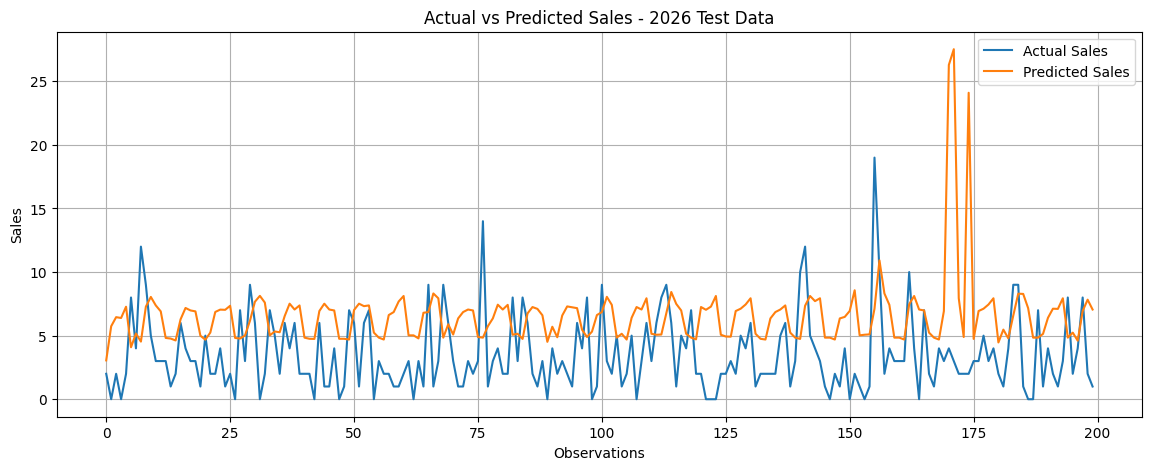

In [183]:
import matplotlib.pyplot as plt

# Select 200 test observations
comparison_df = pd.DataFrame({
    "Actual Sales": y_final_test[:200],
    "Predicted Sales": final_predictions[:200]
})

# Plot actual vs predicted sales
plt.figure(figsize=(14, 5))

plt.plot(
    comparison_df["Actual Sales"].values,
    label="Actual Sales"
)

plt.plot(
    comparison_df["Predicted Sales"].values,
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales - 2026 Test Data")
plt.xlabel("Observations")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

# 11. Weekly and mothly forecasting

## Check the latest date and series coverage

Forecasting requires recent history for every store-family pair. This cell checks that all 1,782 combinations have enough observations.

In [184]:
# Get the latest available date
latest_date = unified_df["date"].max()

# Count records for each store and product family
series_counts = unified_df.groupby(
    ["store_nbr", "family"]
).size()

print("Latest available date:", latest_date)

print("Number of stores:",
      unified_df["store_nbr"].nunique())

print("Number of product families:",
      unified_df["family"].nunique())

print("Total store-family combinations:",
      len(series_counts))

print("Minimum records per combination:",
      series_counts.min())

print("Maximum records per combination:",
      series_counts.max())

Latest available date: 2026-11-17 00:00:00
Number of stores: 54
Number of product families: 33
Total store-family combinations: 1782
Minimum records per combination: 4913
Maximum records per combination: 4913


## Preapre the latest 14 sales observation for each series

The forecast model needs lag_1, lag_7, lag_14 and a seven-observation rolling mean. We store the most recent 14 values for each store-family pair.

In [185]:
# Get the latest 14 observations for every store-family combination
recent_data = (
    unified_df.groupby(
        ["store_nbr", "family"],
        sort=False
    )
    .tail(14)
)

# Create historical sales dictionary
history = {}

for (store, family), group in recent_data.groupby(
    ["store_nbr", "family"],
    sort=False
):
    history[(store, family)] = group["sales"].tolist()

print("Historical data prepared successfully!")
print("Store-family combinations:", len(history))
print("Observations per combination:",
      len(next(iter(history.values()))))

Historical data prepared successfully!
Store-family combinations: 1782
Observations per combination: 14


## Define recursive multiday forecasting

The function predicts one future day at a time. Each day's predictions are appended to history and become lag inputs for the next day. Future promotions are assumed to be zero.

In [186]:
def generate_forecast(days):

    # Copy historical sales so each forecast starts fresh
    forecast_history = {
        key: values.copy()
        for key, values in history.items()
    }

    forecast_results = []

    latest_date = unified_df["date"].max()

    # Generate predictions day by day
    for day in range(1, days + 1):

        forecast_date = latest_date + pd.Timedelta(days=day)

        daily_data = []

        for (store, family), sales_history in forecast_history.items():

            row = {
                "store_nbr": store,
                "family": family,
                "onpromotion": 0,
                "year": forecast_date.year,
                "month": forecast_date.month,
                "day": forecast_date.day,
                "day_of_week": forecast_date.dayofweek,
                "lag_1": sales_history[-1],
                "lag_7": sales_history[-7],
                "lag_14": sales_history[-14],
                "rolling_mean_7": np.mean(sales_history[-7:])
            }

            daily_data.append(row)

        # Prepare prediction dataframe
        forecast_input = pd.DataFrame(daily_data)

        # Preserve categorical family information
        forecast_input["family"] = pd.Categorical(
            forecast_input["family"],
            categories=family_categories
        )

        forecast_input = forecast_input[feature_columns]

        # Predict sales
        predictions = final_hgb_model.predict(forecast_input)

        # Prevent negative demand predictions
        predictions = np.maximum(predictions, 0)

        # Save predictions and update history
        for i, (store, family) in enumerate(forecast_history.keys()):

            predicted_sales = predictions[i]

            forecast_results.append({
                "date": forecast_date,
                "store_nbr": store,
                "family": family,
                "predicted_sales": predicted_sales
            })

            forecast_history[(store, family)].append(
                predicted_sales
            )

    return pd.DataFrame(forecast_results)

##  Generate the 7 day forecast

In [187]:
weekly_forecast = generate_forecast(7)

print("Weekly forecast generated!")
print("Shape:", weekly_forecast.shape)

display(weekly_forecast.head())

Weekly forecast generated!
Shape: (12474, 4)


,date,store_nbr,family,predicted_sales
0,2026-11-18,1,AUTOMOTIVE,5.237371
1,2026-11-18,1,BABY CARE,2.959743
2,2026-11-18,1,BEAUTY,2.959743
3,2026-11-18,1,BEVERAGES,944.698068
4,2026-11-18,1,BOOKS,2.959743


## Generate monthly forecast

In [188]:
monthly_forecast = generate_forecast(30)

print("Monthly forecast generated!")
print("Shape:", monthly_forecast.shape)

display(monthly_forecast.head())

Monthly forecast generated!
Shape: (53460, 4)


,date,store_nbr,family,predicted_sales
0,2026-11-18,1,AUTOMOTIVE,5.237371
1,2026-11-18,1,BABY CARE,2.959743
2,2026-11-18,1,BEAUTY,2.959743
3,2026-11-18,1,BEVERAGES,944.698068
4,2026-11-18,1,BOOKS,2.959743


## save weekly and monthly forecast files

In [189]:
import os

os.makedirs("artifacts", exist_ok=True)

weekly_forecast.to_csv(
    "artifacts/weekly_forecast.csv",
    index=False
)

monthly_forecast.to_csv(
    "artifacts/monthly_forecast.csv",
    index=False
)

print("Both forecasts saved successfully!")

Both forecasts saved successfully!


## Validate the saved forecast files

We reload the CSV files and check shape, date coverage, missing values and duplicate rows to ensure the exports are usable.

In [190]:
import pandas as pd

weekly_df = pd.read_csv("artifacts/weekly_forecast.csv")
monthly_df = pd.read_csv("artifacts/monthly_forecast.csv")

# Convert date column to datetime
weekly_df["date"] = pd.to_datetime(weekly_df["date"])
monthly_df["date"] = pd.to_datetime(monthly_df["date"])

print("WEEKLY FORECAST")
print("Shape:", weekly_df.shape)
print("Date range:", weekly_df["date"].min(), "to", weekly_df["date"].max())
print("Missing values:", weekly_df.isnull().sum().sum())
print("Duplicate rows:", weekly_df.duplicated().sum())

print("\nMONTHLY FORECAST")
print("Shape:", monthly_df.shape)
print("Date range:", monthly_df["date"].min(), "to", monthly_df["date"].max())
print("Missing values:", monthly_df.isnull().sum().sum())
print("Duplicate rows:", monthly_df.duplicated().sum())

WEEKLY FORECAST
Shape: (12474, 4)
Date range: 2026-11-18 00:00:00 to 2026-11-24 00:00:00
Missing values: 0
Duplicate rows: 0

MONTHLY FORECAST
Shape: (53460, 4)
Date range: 2026-11-18 00:00:00 to 2026-12-17 00:00:00
Missing values: 0
Duplicate rows: 0


# 12. Inventory and Reorder recommendaations

## Create simulated current stock records

The source dataset has sales but no real inventory-on-hand column. Therefore, current stock is simulated as a random multiple of 2 to 12 days of average forecast demand.

In [191]:
import pandas as pd
import numpy as np

# Load the weekly forecast
weekly_forecast = pd.read_csv("artifacts/weekly_forecast.csv")

# Calculate average predicted daily demand
average_demand = (
    weekly_forecast.groupby(["store_nbr", "family"])["predicted_sales"]
    .mean()
    .reset_index()
)

average_demand.rename(
    columns={"predicted_sales": "average_daily_demand"},
    inplace=True
)

# Generate simulated current stock
np.random.seed(42)

average_demand["current_stock"] = (
    average_demand["average_daily_demand"] *
    np.random.uniform(2, 12, size=len(average_demand))
).round().astype(int)

print("Inventory dataset created!")
print("Shape:", average_demand.shape)

average_demand.head()

Inventory dataset created!
Shape: (1782, 4)


,store_nbr,family,average_daily_demand,current_stock
0,1,AUTOMOTIVE,6.441268,37
1,1,BABY CARE,4.326161,50
2,1,BEAUTY,4.396048,41
3,1,BEVERAGES,1017.245670,8124
4,1,BOOKS,4.326161,15


## Calculate safety stock, reorder points and stock status

The project assumes three days of replenishment lead time and two days of safety stock. A reorder alert is raised when current stock is at or below the reorder point.

In [192]:
# Inventory planning assumptions
lead_time = 3
safety_stock_days = 2

# Calculate safety stock
average_demand["safety_stock"] = (
    average_demand["average_daily_demand"] * safety_stock_days
).round()

# Calculate reorder point
average_demand["reorder_point"] = (
    average_demand["average_daily_demand"] * lead_time
    + average_demand["safety_stock"]
).round()

# Determine stock status
average_demand["stock_status"] = np.where(
    average_demand["current_stock"] <= average_demand["reorder_point"],
    "REORDER NOW",
    "SUFFICIENT STOCK"
)

print("Reorder points calculated successfully!")

average_demand.head(10)

Reorder points calculated successfully!


,store_nbr,family,average_daily_demand,current_stock,safety_stock,reorder_point,stock_status
0,1,AUTOMOTIVE,6.441268,37,13.0,32.0,SUFFICIENT STOCK
1,1,BABY CARE,4.326161,50,9.0,22.0,SUFFICIENT STOCK
2,1,BEAUTY,4.396048,41,9.0,22.0,SUFFICIENT STOCK
3,1,BEVERAGES,1017.245670,8124,2034.0,5086.0,SUFFICIENT STOCK
4,1,BOOKS,4.326161,15,9.0,22.0,REORDER NOW
5,1,BREAD/BAKERY,284.418965,1013,569.0,1422.0,REORDER NOW
6,1,CELEBRATION,7.320468,19,15.0,37.0,REORDER NOW
7,1,CLEANING,538.853442,5745,1078.0,2695.0,SUFFICIENT STOCK
8,1,DAIRY,499.186429,3999,998.0,2496.0,SUFFICIENT STOCK
9,1,DELI,102.980187,935,206.0,515.0,SUFFICIENT STOCK


## Calculate target stock and recommended order quantity

Target stock covers seven days of average demand plus safety stock. The recommended order quantity is the positive gap between target stock and current stock; otherwise it is zero.

In [193]:
# Target inventory coverage
target_stock_days = 7

# Calculate target stock
average_demand["target_stock"] = (
    average_demand["average_daily_demand"] * target_stock_days
    + average_demand["safety_stock"]
).round()

# Calculate recommended order quantity
average_demand["recommended_order_qty"] = (
    average_demand["target_stock"] - average_demand["current_stock"]
).clip(lower=0).round().astype(int)

# Display results
print("Recommended order quantities calculated!")

average_demand.head(10)

Recommended order quantities calculated!


,store_nbr,family,average_daily_demand,current_stock,safety_stock,reorder_point,stock_status,target_stock,recommended_order_qty
0,1,AUTOMOTIVE,6.441268,37,13.0,32.0,SUFFICIENT STOCK,58.0,21
1,1,BABY CARE,4.326161,50,9.0,22.0,SUFFICIENT STOCK,39.0,0
2,1,BEAUTY,4.396048,41,9.0,22.0,SUFFICIENT STOCK,40.0,0
3,1,BEVERAGES,1017.245670,8124,2034.0,5086.0,SUFFICIENT STOCK,9155.0,1031
4,1,BOOKS,4.326161,15,9.0,22.0,REORDER NOW,39.0,24
5,1,BREAD/BAKERY,284.418965,1013,569.0,1422.0,REORDER NOW,2560.0,1547
6,1,CELEBRATION,7.320468,19,15.0,37.0,REORDER NOW,66.0,47
7,1,CLEANING,538.853442,5745,1078.0,2695.0,SUFFICIENT STOCK,4850.0,0
8,1,DAIRY,499.186429,3999,998.0,2496.0,SUFFICIENT STOCK,4492.0,493
9,1,DELI,102.980187,935,206.0,515.0,SUFFICIENT STOCK,927.0,0


## Select final inventory columns and save th einventory csv

Only the columns needed by the inventory dashboard and reorder report are retained. The summary counts how many records need reordering and totals the recommended units.

In [194]:
# Select final inventory columns
inventory_df = average_demand[
    [
        "store_nbr",
        "family",
        "average_daily_demand",
        "current_stock",
        "safety_stock",
        "reorder_point",
        "target_stock",
        "recommended_order_qty",
        "stock_status"
    ]
].copy()

# Save inventory dataset
inventory_df.to_csv(
    "artifacts/inventory.csv",
    index=False
)

print("Inventory dataset saved successfully!")
print("Shape:", inventory_df.shape)

# Check stock status summary
print("\nStock Status Summary:")
print(inventory_df["stock_status"].value_counts())

# Check total recommended order quantity
print(
    "\nTotal Recommended Order Quantity:",
    inventory_df["recommended_order_qty"].sum()
)

Inventory dataset saved successfully!
Shape: (1782, 9)

Stock Status Summary:
stock_status
SUFFICIENT STOCK    1212
REORDER NOW          570
Name: count, dtype: int64

Total Recommended Order Quantity: 1204432


# Final interpretation and project notes

## What the results mean

- The final HistGradientBoosting model achieved approximately **MAE 101.87**, **RMSE 367.28** and **R² 0.8814** on the reserved 2026 synthetic test records in this experiment.
- The 7-day forecast contains **12,474 rows**: 7 days × 54 stores × 33 product families.
- The 30-day forecast contains **53,460 rows**: 30 days × 54 stores × 33 product families.
- The inventory file contains **1,782 rows**: one record per store-family pair.
- In the generated inventory scenario, **570** records were marked `REORDER NOW` and **1,212** were marked `SUFFICIENT STOCK`.

## Important concepts to explain in a presentation

- **Lag features:** previous observed sales values used as model inputs.
- **Rolling mean:** average of the previous seven sales observations, shifted so the current target is excluded.
- **Chronological validation:** training on earlier periods and validating on later periods to respect time order.
- **MAE:** average absolute prediction error.
- **RMSE:** square root of average squared error; it penalizes large misses more heavily.
- **R²:** proportion of target variance explained by the model relative to a mean baseline.
- **Permutation importance:** change in validation error after shuffling one feature; it indicates predictive usefulness, not causation.
- **Recursive forecasting:** each predicted day is fed into the history used to predict the next day.
- **Reorder point:** lead-time demand plus safety stock.
- **Recommended order quantity:** the positive difference between target stock and current stock.

## Limitations to state clearly

1. The post-August-2017 records are synthetic, not actual observations.
2. The 2026 evaluation therefore does not establish real-world 2026 forecasting accuracy.
3. Future promotions are assumed to be zero during forecasting.
4. Current stock is simulated, not obtained from real store inventory systems.
5. The 30-day recursive forecast may accumulate prediction errors.
6. The lag features are based on previous rows within each store-family series. Because the historical and synthetic periods have a calendar gap, they should not be described as verified consecutive real daily observations across that gap.
